# CellQuorum Python API walkthrough

The command line (`cellquorum run --config ...`) is the usual way to run an analysis. This notebook shows
the same engine from Python: load a configuration as an object, run one stage at a time and look at what
each stage reports, then run the whole pipeline and read its outputs. Nothing here is a second
implementation. The notebook calls (`cq.pp`, `cq.tl`) run the same registered stages the command line
runs, so what you see here is what a config-driven run produces.

The data are the four-donor subset of GSE140819 (Slyper et al. 2020, *Nat Med*) described in the
GSE140819 data: each donor has a whole-cell and a nuclei
library, so the design is paired and the donor is the unit of replication.

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd

import cellquorum as cq
from cellquorum.config.loader import load_config
from cellquorum.version import __version__

warnings.filterwarnings("ignore", category=FutureWarning)
# The repository root, whether this runs from docs/tutorials or from a Jupyter started at the root.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").is_dir())
print("CellQuorum", __version__)

CellQuorum 0.1.0


## 1. The data

`scripts/prepare_gse140819_tutorial.py` downloads the GEO archive (1.2 GB, once) and writes the prepared
object. The next cell runs it if the file is not there yet.

In [2]:
from cellquorum.datasets import _gse140819 as gse

PREPARED = gse.dataset_dir() / "tutorial.h5ad"
if not PREPARED.exists():
    import runpy

    runpy.run_path(str(ROOT / "scripts" / "prepare_gse140819_tutorial.py"), run_name="__main__")

adata = ad.read_h5ad(PREPARED)
print(adata)
adata.obs.groupby(["donor", "condition"], observed=True).size().unstack(fill_value=0)

AnnData object with n_obs × n_vars = 15000 × 20233
    obs: 'barcode', 'sample_id', 'donor_id', 'assay', 'protocol', 'truth_annotate', 'truth_doublet', 'truth_percent_mito', 'truth_nUMI', 'truth_nGene', 'sample', 'donor', 'condition', 'cell_type'
    layers: 'counts'


condition,cells,nuclei
donor,,
CLL-pilot1,1038,948
HTAPP-656-SMP-3481,1397,3164
HTAPP-963-SMP-4741,2092,2941
HTAPP-StJude-SMP-PDX1,1416,2004


Raw counts are in `adata.layers["counts"]`. The columns the configuration names are `sample` (the library),
`donor`, `condition` (`cells` or `nuclei`) and `cell_type` (the authors' labels, used here as given).

To keep this notebook quick we work with a random 4,000-cell subset. The full pipeline run in section 5 uses
the same subset; the tutorial page shows the 15,000-cell run.

In [3]:
rng = np.random.default_rng(0)
subset = adata[np.sort(rng.choice(adata.n_obs, 4000, replace=False))].copy()
subset.obs.groupby(["donor", "condition"], observed=True).size().unstack(fill_value=0)

condition,cells,nuclei
donor,,
CLL-pilot1,278,254
HTAPP-656-SMP-3481,358,847
HTAPP-963-SMP-4741,550,801
HTAPP-StJude-SMP-PDX1,374,538


## 2. The configuration is an object

`load_config` reads and validates the YAML. Validation is strict: an unknown setting, a misspelt key or an
impossible combination is an error at load time, before any stage runs.

In [4]:
cfg = load_config(ROOT / "configs" / "gse140819_tutorial.yaml")
print("design:   ", cfg.design.model_dump())
print("cohort:   ", {k: v for k, v in cfg.cohort.model_dump().items() if v})
print("nuclei:   ", cfg.qc_evidence.graded.nuclei_key, cfg.qc_evidence.graded.nuclei_values)

design:    {'donor_col': 'donor', 'condition_col': 'condition', 'case': 'nuclei', 'control': 'cells', 'paired': True, 'factorial': None}
cohort:    {'sample_key': 'sample', 'donor_key': 'donor', 'condition_key': 'condition', 'batch_key': 'donor', 'condition_levels': ['cells', 'nuclei'], 'focus': {'label_key': None, 'labels': []}}
nuclei:    condition ['nuclei']


Two examples of what strict validation catches. A `methods:` entry must name its method with `method:`;
without it the stage would quietly run its default instead.

In [5]:
from pydantic import ValidationError

try:
    load_config(
        {**cfg.model_dump(), "differential_abundance": {"methods": [{"name": "proportion_ttest"}]}}
    )
except (ValidationError, Exception) as error:
    print(type(error).__name__)
    print(str(error)[:400])

TypeError
argument should be a str or an os.PathLike object where __fspath__ returns a str, not 'dict'


And the nuclear-integrity setting. Naming the nuclei **and** switching the axis off for the whole run would
be the same decision written twice, so it is refused.

In [6]:
from cellquorum.stages.qc.config import QCGradedConfig

try:
    QCGradedConfig(nuclear_axis_applicable=False, nuclei_key="condition", nuclei_values=["nuclei"])
except ValidationError as error:
    print(str(error).splitlines()[-1][:300])

    For further information visit https://errors.pydantic.dev/2.13/v/value_error


## 3. One stage at a time

Each notebook call takes the AnnData and the configuration, runs one stage and returns a
`NotebookStageOutput`: the updated AnnData plus the stage's metrics, notes and warnings. We start with QC.

The QC stage scores every cell on several independent kinds of evidence (capture complexity, metabolic
stress, nuclear integrity) and calls it `core`, `borderline` or `quarantine`; it removes nothing. The
nuclear-integrity axis (MALAT1) means damage in a whole cell but is the expected signal in a nucleus, so the
configuration names the nuclei and the axis is switched off for them only.

In [7]:
out_dir = ROOT / "runs" / "api_walkthrough"  # outside docs/, which the site build scans
qc = cq.pp.qc(subset, config=cfg, output_dir=out_dir / "qc")
data = qc.adata
print("warnings:", len(qc.warnings), "| notes:", len(qc.notes))
pd.crosstab(data.obs["condition"], data.obs["qc_state_initial"])

/home/ajbook/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


I0000 00:00:1793977577.767937    9981 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793977577.809494    9981 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793977579.466197    9981 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


/home/ajbook/projects/cellquorum/src/cellquorum/visualization/figstyle.py:1052: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


/home/ajbook/projects/cellquorum/src/cellquorum/visualization/figstyle.py:1052: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


/home/ajbook/projects/cellquorum/src/cellquorum/visualization/figstyle.py:1052: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


/home/ajbook/projects/cellquorum/src/cellquorum/visualization/figstyle.py:1052: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


warnings: 0 | notes: 3


qc_state_initial,borderline,core,quarantine
condition,,,
cells,77,1477,6
nuclei,140,2298,1


In [8]:
# The nuclear axis: scored for whole cells, not applicable for nuclei.
pd.crosstab(data.obs["condition"], data.obs["qc_ev_malat1_fraction_availability"])

qc_ev_malat1_fraction_availability,available_valid,not_applicable
condition,,
cells,1560,0
nuclei,0,2439


Because a nucleus has one evidence family fewer, its **evidence coverage** is lower, and the QC design says
so on purpose: a verdict reached on fewer families is reported with less certainty.

In [9]:
data.obs.groupby("condition", observed=True)["qc_evidence_coverage"].agg(["mean", "min", "max"])

,mean,min,max
condition,,,
cells,1.000000,1.000000,1.000000
nuclei,0.666667,0.666667,0.666667


Next normalisation, feature selection, PCA, Harmony integration over the donor, and clustering. Each call
reads its settings from the configuration, so nothing is repeated here. The configuration names the
normalisation recipe (`cellquorum_log1p_cp10k_v1`, log1p of counts per 10,000); the default recipe needs a
separate environment, which a fresh install does not have.

In [10]:
data = cq.pp.normalize(data, config=cfg, output_dir=out_dir / "norm").adata
data = cq.pp.select_features(data, config=cfg, output_dir=out_dir / "hvg").adata
data = cq.tl.reduce_dimensions(data, config=cfg, output_dir=out_dir / "pca").adata
integrated = cq.tl.integrate(data, config=cfg, output_dir=out_dir / "integration")
data = integrated.adata
print("integration batch key:", integrated.metrics.get("batch_key"))
print("obsm:", list(data.obsm))

n_pcs=auto selected only 6 of up to 50 PCs (26.9% cumulative variance). The kneedle elbow is known to under-select on scRNA variance curves; set an explicit n_pcs (e.g. 50) if downstream steps use the PCA embedding.


integration batch key: None
obsm: ['X_qc_provisional', 'X_pca', 'X_pca_harmony']


In [11]:
clustered = cq.tl.cluster(data, config=cfg, output_dir=out_dir / "clustering")
data = clustered.adata
data.obs["leiden"].value_counts().sort_index().head(10)

leiden
0    212
1    279
2    234
3    427
4    156
5    274
6    396
7    181
8    132
9     51
Name: count, dtype: int64

Cluster identity against the authors' labels, as a sanity check that the integrated space separates cell
types and not preparations:

In [12]:
pd.crosstab(data.obs["cell_type"], data.obs["leiden"]).iloc[:, :9]

leiden,0,1,2,3,4,5,6,7,8
cell_type,,,,,,,,,
B cell,111,134,7,1,15,6,126,93,0
Endothelial cell,0,1,0,4,0,136,31,4,49
Epithelial cell,0,0,2,0,0,5,6,13,0
Fibroblast,0,0,2,0,0,45,29,0,79
Hepatocyte,0,0,8,0,0,0,0,0,2
Macrophage,8,1,4,23,6,27,90,15,0
NK cell,3,3,0,124,22,0,0,0,0
Neural crest,0,0,0,0,0,8,4,0,2
Neuroendocrine,57,85,176,56,0,29,8,28,0


## 4. Reading the stage output

`NotebookStageOutput` also carries the underlying `StageResult`, with the artifacts the stage wrote.

In [13]:
print(sorted(qc.metrics)[:8])
print([a.name if hasattr(a, "name") else str(a) for a in qc.result.artifacts][:6])

['ambient_correction', 'artifact_manifest', 'attrition_audit', 'enabled', 'floor_summary', 'floors', 'graded', 'input_shape']
['qc_donor_comparisons', 'qc_cell_metrics', 'qc_gene_metrics', 'qc_feature_masks', 'qc_cell_floors', 'qc_gene_floors']


## 5. The whole pipeline in one call

`cq.run_pipeline` takes a path, a validated configuration object, or a plain dictionary. Here it gets the
tutorial configuration with the input pointed at our subset. Every stage is named in that configuration, so
exactly the stages we want run and nothing else.

In [14]:
subset_path = out_dir / "subset.h5ad"
out_dir.mkdir(exist_ok=True)
subset.write_h5ad(subset_path)

config = cfg.model_dump(mode="json")
config["input"]["h5ad"] = str(subset_path)
config["compute"]["backend"] = "cpu"

result = cq.run_pipeline(config=config, output_dir=out_dir / "run", quiet=True)
records = result.execution_result.stage_execution_records
ran = [r.stage_name for r in records if r.status == "success"]
print("ran:", ", ".join(ran))

/home/ajbook/projects/cellquorum/src/cellquorum/visualization/figstyle.py:1052: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


/home/ajbook/projects/cellquorum/src/cellquorum/visualization/figstyle.py:1052: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


/home/ajbook/projects/cellquorum/src/cellquorum/visualization/figstyle.py:1052: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


/home/ajbook/projects/cellquorum/src/cellquorum/visualization/figstyle.py:1052: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


n_pcs=auto selected only 6 of up to 50 PCs (26.9% cumulative variance). The kneedle elbow is known to under-select on scRNA variance curves; set an explicit n_pcs (e.g. 50) if downstream steps use the PCA embedding.


8 file(s) in results/ and figures/ predate this run (0.8 MB). This run did not write them. If the directory was reused, each one is an artifact for an entity this run no longer produces (a skipped group, a merged cluster, a pathway below threshold) and is indistinguishable on disk from a current result. Inventory: provenance/inherited_artifacts.csv
    figures/preprocessing/normalization_depth_correlation_before_after.png  (0.2 MB)
    figures/preprocessing/normalization_gene_mean_variance.png  (0.1 MB)
    figures/preprocessing/normalization_expression_distribution_before_after.png  (0.1 MB)
    figures/preprocessing/normalization_total_counts_before_after.png  (0.1 MB)
    figures/preprocessing/normalization_depth_correlation_before_after.pdf  (0.1 MB)
    figures/preprocessing/normalization_gene_mean_variance.pdf  (0.0 MB)
    figures/preprocessing/normalization_expression_distribution_before_after.pdf  (0.0 MB)
    figures/preprocessing/normalization_total_counts_before_after.pdf  

ran: qc_evidence, preprocessing, feature_selection, dimensionality, integration, clustering, embeddings, composition, differential_abundance


In [15]:
run = out_dir / "run"
pd.read_csv(run / "results" / "composition_by_condition.csv").round(2).head(12)

,condition,Neuroendocrine,T cell,B cell,Epithelial cell,Endothelial cell,Fibroblast,Macrophage,NK cell,Hepatocyte,Zona glomerulosa,Neural crest
0,cells,24.10,28.85,17.18,4.42,3.53,5.19,5.77,9.81,0.71,0.32,0.13
1,nuclei,26.69,6.23,9.23,16.07,13.33,6.93,6.03,0.00,5.78,5.33,4.39


In [16]:
da = pd.read_csv(run / "results" / "da_proportion_ttest.csv")
columns = ["cell_type", "control_mean_pct", "case_mean_pct", "effect_pp", "pvalue", "fdr"]
da[[*columns, "design_floor_p"]].round(3)

,cell_type,control_mean_pct,case_mean_pct,effect_pp,pvalue,fdr,design_floor_p
0,B cell,23.471,22.011,-1.460,0.122,0.430,0.125
1,Endothelial cell,3.280,9.689,6.409,0.312,0.430,0.125
2,Epithelial cell,3.136,12.235,9.098,0.391,0.430,0.125
3,Fibroblast,5.583,5.007,-0.576,0.881,0.881,0.125
4,Hepatocyte,0.500,4.401,3.901,0.391,0.430,0.125
5,Macrophage,4.817,5.120,0.303,0.319,0.430,0.125
6,NK cell,8.807,0.000,-8.807,0.186,0.430,0.125
7,Neural crest,0.140,3.162,3.022,0.391,0.430,0.125
8,Neuroendocrine,25.140,28.339,3.200,0.391,0.430,0.125
9,T cell,24.777,6.195,-18.582,0.199,0.430,0.125


With four donors the smallest p-value a paired exact test can reach is 0.125, so no cell type can reach
FDR significance here, and the stage reports that floor (`design_floor_p`) next to every result instead of
leaving the reader to wonder. The differences are descriptive; the tutorial page discusses what to do about
it (more donors).

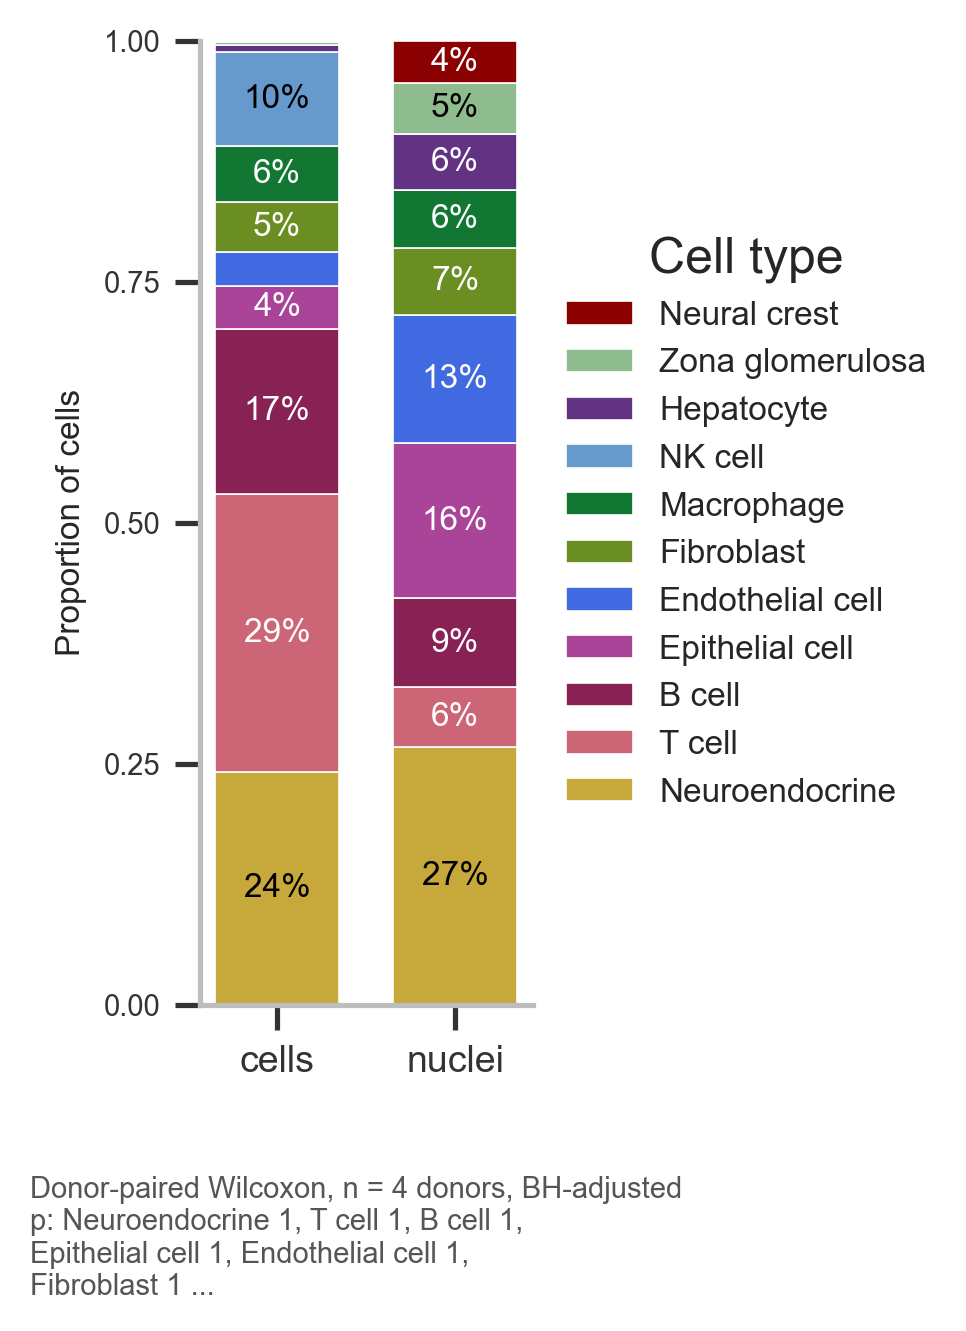

In [17]:
from IPython.display import Image

Image(filename=str(run / "figures" / "composition" / "composition_by_condition.png"), width=360)

## 6. Reusing a primitive

The statistical building blocks are importable on their own. `aggregate_pseudobulk` turns cells into one
row per donor and condition, which is what the donor-level tests use as the unit.

In [18]:
pb = cq.utils.aggregate_pseudobulk(
    data, layer="counts", donor_col="donor", condition_col="condition"
)
print(type(pb).__name__)
print({k: getattr(v, "shape", None) for k, v in vars(pb).items() if hasattr(v, "shape")})

PseudobulkResult
{'counts': (8, 16912), 'sample_meta': (8, 2), 'n_cells': (8,)}


## Where next

- The same run from the command line: `cellquorum run --config configs/gse140819_tutorial.yaml`.
- [Configuration guide](../guide/configuration.md) and [Python API reference](../reference/api.md).